	Predicting Stock Market Prices	Apply advanced interpolation techniques to address missing values in the TSLA dataset, ensuring continuity and accuracy in the time series while preserving data trends.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [2]:
data = pd.read_csv(
    "TSLA_datetime_processed.csv",
    parse_dates=["Date"],
    index_col="Date"
)

data = data.sort_index()

print("Dataset Shape:", data.shape)
display(data.head())

Dataset Shape: (100, 10)


,Open,High,Low,Close,Volume,Year,Month,Day,Day_Name,Weekday
Date,,,,,,,,,,
2025-01-02,377.53,386.12,374.68,381.88,97077442,2025,1,2,Thursday,3
2025-01-03,372.39,377.55,371.43,376.36,85746412,2025,1,3,Friday,4
2025-01-06,377.69,381.99,373.44,380.68,56893889,2025,1,6,Monday,0
2025-01-07,387.26,390.45,385.32,386.06,76990555,2025,1,7,Tuesday,1
2025-01-08,372.81,379.96,368.15,375.53,100413036,2025,1,8,Wednesday,2


In [3]:
print("Missing Values Before Interpolation:")
print(data.isnull().sum())

print("\nTotal Missing Values:", data.isnull().sum().sum())

Missing Values Before Interpolation:
Open        0
High        0
Low         0
Close       0
Volume      0
Year        0
Month       0
Day         0
Day_Name    0
Weekday     0
dtype: int64

Total Missing Values: 0


In [4]:
test_data = data.copy()

numeric_columns = ["Open", "High", "Low", "Close", "Volume"]

# Introduce missing values in selected rows
test_data.loc[test_data.index[10:13], "Close"] = np.nan
test_data.loc[test_data.index[25:28], "Open"] = np.nan
test_data.loc[test_data.index[40:43], "Volume"] = np.nan

print("Missing Values Introduced:")
print(test_data[numeric_columns].isnull().sum())

Missing Values Introduced:
Open      3
High      0
Low       0
Close     3
Volume    3
dtype: int64


In [5]:
linear_data = test_data.copy()

linear_data[numeric_columns] = (
    linear_data[numeric_columns]
    .interpolate(method="linear", limit_area="inside")
)

print("Linear Interpolation Completed")
print(linear_data[numeric_columns].isnull().sum())

Linear Interpolation Completed
Open      0
High      0
Low       0
Close     0
Volume    0
dtype: int64


In [6]:
time_data = test_data.copy()

time_data[numeric_columns] = (
    time_data[numeric_columns]
    .interpolate(method="time", limit_area="inside")
)

print("Time-Based Interpolation Completed")
print(time_data[numeric_columns].isnull().sum())

Time-Based Interpolation Completed
Open      0
High      0
Low       0
Close     0
Volume    0
dtype: int64


In [8]:
polynomial_data = test_data.copy()

# Use numerical index for polynomial interpolation
polynomial_data[numeric_columns] = (
    polynomial_data[numeric_columns]
    .reset_index(drop=True)
    .interpolate(
        method="polynomial",
        order=2,
        limit_area="inside"
    )
    .set_axis(polynomial_data.index)
)

print("Polynomial Interpolation Completed")

print(polynomial_data[numeric_columns].isnull().sum())

Polynomial Interpolation Completed
Open      0
High      0
Low       0
Close     0
Volume    0
dtype: int64


In [9]:
comparison = pd.DataFrame({
    "Original Missing": test_data[numeric_columns].isnull().sum(),
    "Linear": linear_data[numeric_columns].isnull().sum(),
    "Time Based": time_data[numeric_columns].isnull().sum(),
    "Polynomial": polynomial_data[numeric_columns].isnull().sum()
})

display(comparison)

,Original Missing,Linear,Time Based,Polynomial
Open,3,0,0,0
High,0,0,0,0
Low,0,0,0,0
Close,3,0,0,0
Volume,3,0,0,0


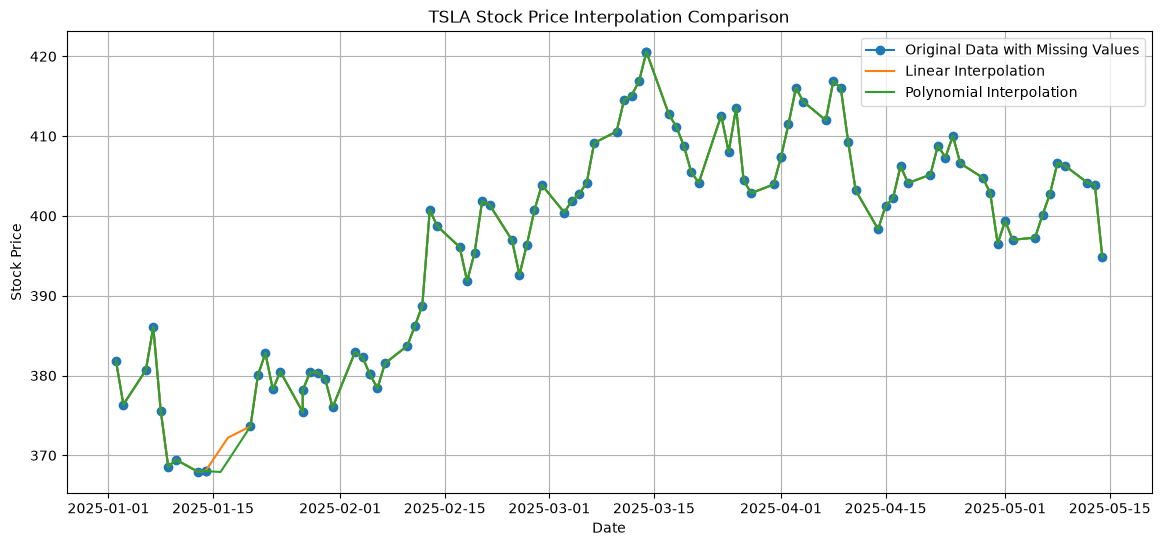

In [10]:
plt.figure(figsize=(14, 6))

plt.plot(
    test_data.index,
    test_data["Close"],
    label="Original Data with Missing Values",
    marker="o"
)

plt.plot(
    linear_data.index,
    linear_data["Close"],
    label="Linear Interpolation"
)

plt.plot(
    polynomial_data.index,
    polynomial_data["Close"],
    label="Polynomial Interpolation"
)

plt.title("TSLA Stock Price Interpolation Comparison")
plt.xlabel("Date")
plt.ylabel("Stock Price")
plt.legend()
plt.grid(True)
plt.show()

In [11]:
clean_data = time_data.copy()

print("Remaining Missing Values:")
print(clean_data.isnull().sum())

Remaining Missing Values:
Open        0
High        0
Low         0
Close       0
Volume      0
Year        0
Month       0
Day         0
Day_Name    0
Weekday     0
dtype: int64


In [12]:
print("Final Dataset Shape:", clean_data.shape)

print("Total Missing Values:",
      clean_data.isnull().sum().sum())

print("Date Index:", clean_data.index.dtype)

print("Chronological Order:",
      clean_data.index.is_monotonic_increasing)

display(clean_data.head(10))

Final Dataset Shape: (100, 10)
Total Missing Values: 0
Date Index: datetime64[us]
Chronological Order: True


,Open,High,Low,Close,Volume,Year,Month,Day,Day_Name,Weekday
Date,,,,,,,,,,
2025-01-02,377.53,386.12,374.68,381.88,97077442.0,2025,1,2,Thursday,3
2025-01-03,372.39,377.55,371.43,376.36,85746412.0,2025,1,3,Friday,4
2025-01-06,377.69,381.99,373.44,380.68,56893889.0,2025,1,6,Monday,0
2025-01-07,387.26,390.45,385.32,386.06,76990555.0,2025,1,7,Tuesday,1
2025-01-08,372.81,379.96,368.15,375.53,100413036.0,2025,1,8,Wednesday,2
2025-01-09,367.43,369.95,366.48,368.56,128863681.0,2025,1,9,Thursday,3
2025-01-10,373.36,375.26,365.17,369.47,45415699.0,2025,1,10,Friday,4
2025-01-13,366.86,371.93,362.30,367.93,106009620.0,2025,1,13,Monday,0
2025-01-14,370.25,375.12,363.13,368.04,116938633.0,2025,1,14,Tuesday,1


In [13]:
clean_data.to_csv("TSLA_interpolated_data.csv")

print("Interpolated dataset saved successfully!")

Interpolated dataset saved successfully!



# TSLA Stock Data – Missing Value Interpolation

## Objectives
- Identify missing values in the TSLA dataset.
- Apply linear interpolation.
- Apply time-based interpolation.
- Apply polynomial interpolation.
- Compare interpolation results.
- Preserve continuity in stock price data.

## Methodology
1. Loaded the datetime-processed TSLA dataset.
2. Identified existing missing values.
3. Introduced sample missing values for testing.
4. Applied linear interpolation.
5. Applied time-based interpolation.
6. Applied polynomial interpolation.
7. Compared missing-value counts and visualized results.
8. Saved the selected interpolated dataset.

## Conclusion
Different interpolation techniques were implemented to handle missing stock values. Linear, time-based, and polynomial interpolation methods were compared. Time-based interpolation was selected for this exercise to account for date intervals and maintain continuity in the time series.

Note: Sample missing values were introduced for demonstration. Interpolated values are estimates, not actual market prices.
